# 01 · Preparación de datos (VisDrone-DET, copia de Kaggle)
Objetivo: convertir YOLO → COCO JSON, crear subconjuntos y medir la densidad de objetos.
**Decisiones a registrar en `DESIGN_LOG.md`:** subconjunto usado (D4), orden de clases de la copia (D14), tratamiento de cajas inválidas (D8).

Los JSON pequeños (`train_sub.json`, `val.json`, `val_sub.json`) se **commitean** al repo para que los notebooks 02 y 03 corran en otra sesión sin repetir la conversión.

In [1]:
import os, sys, subprocess
REPO_URL = 'https://github.com/OscarLauLu/DETR-1INF52.git'
BRANCH   = 'rodrigo_dev'               # main aún no tiene el avance
REPO_DIR = 'DETR-1INF52'
if not os.path.exists('../src/common.py'):
    if not os.path.exists(f'{REPO_DIR}/src'):
        !git clone -q -b {BRANCH} {REPO_URL} {REPO_DIR}
    os.chdir(f'{REPO_DIR}/notebooks')
    !pip -q install -r ../requirements.txt
sys.path.insert(0, '../src')
from common import *
import torch, json, pandas as pd, matplotlib.pyplot as plt
os.makedirs('../results', exist_ok=True); os.makedirs('../data', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'; SEED = 42; set_seed(SEED)
COMMIT = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
print(DEVICE, '| commit', COMMIT); print(env_report('../results/entorno.txt'))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
cpu | commit d9f38ef
python 3.13.15 | Linux-6.18.55+-x86_64-with-glibc2.39
torch 2.11.0+cpu
torchvision 0.26.0+cpu
transformers 4.57.6
timm 1.0.29
pycocotools ?
scipy 1.16.3
numpy 2.1.3


In [2]:
!find /kaggle/input -maxdepth 4 -type d | head -40

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/banuprasadb
/kaggle/input/datasets/banuprasadb/visdrone-dataset
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset


In [3]:
ROOT = '/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset'
for r, d, f in os.walk(ROOT):
    if r[len(ROOT):].count(os.sep) <= 3:
        print(r, '|', len(f), 'archivos')
!find {ROOT} -name "*.yaml" -o -name "*.yml"

/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset | 1 archivos
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset/VisDrone2019-DET-test-challenge | 0 archivos
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset/VisDrone2019-DET-test-challenge/images | 1580 archivos
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset/VisDrone2019-DET-test-dev | 0 archivos
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset/VisDrone2019-DET-test-dev/labels | 1610 archivos
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset/VisDrone2019-DET-test-dev/images | 1610 archivos
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset/VisDrone2019-DET-train | 0 archivos
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset/VisDrone2019-DET-train/labels | 6471 archivos
/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset/VisDrone2019-DET-train/images | 6471 archivos
/

In [4]:
# Rutas de la copia de Kaggle banuprasadb/visdrone-dataset (formato YOLO)
TRAIN_IMG, TRAIN_LBL = f'{ROOT}/VisDrone2019-DET-train/images', f'{ROOT}/VisDrone2019-DET-train/labels'
VAL_IMG,   VAL_LBL   = f'{ROOT}/VisDrone2019-DET-val/images',   f'{ROOT}/VisDrone2019-DET-val/labels'

# D14 · Orden de clases de la copia: las 10 primeras deben coincidir con VISDRONE_CLASSES,
# porque COCO_TO_VISDRONE (evaluación zero-shot) depende de ese orden.
print(open(f'{ROOT}/visdrone.yaml').read())
names = read_yolo_names(f'{ROOT}/visdrone.yaml'); print(names)
if [n.lower() for n in names[:10]] != VISDRONE_CLASSES:
    print('⚠️ ORDEN DISTINTO en las 10 primeras clases: revisar VISDRONE_CLASSES y COCO_TO_VISDRONE')
if len(names) > 10:
    print('Clases extra (yolo_to_coco las descarta):', names[10:])

# Índices de clase presentes en las etiquetas de val (para saber si aparece 'others' = 10)
from collections import Counter
cls = Counter(int(float(l.split()[0])) for f in os.listdir(VAL_LBL)
              for l in open(os.path.join(VAL_LBL, f)) if l.strip())
print(sorted(cls.items()))

# VisDrone Dataset Configuration
path: ./VisDrone_Dataset
train: VisDrone2019-DET-train/images
val: VisDrone2019-DET-val/images
test: VisDrone2019-DET-test-dev/images

#number of classes
nc: 10

# Class names
names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor

['pedestrian', 'people', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'awning-tricycle', 'bus', 'motor']
[(0, 8844), (1, 5125), (2, 1287), (3, 14064), (4, 1975), (5, 750), (6, 1045), (7, 532), (8, 251), (9, 4886)]


In [5]:
# D4 · Solo se convierten las 600 imágenes de train del subconjunto (semilla 42) y val completo.
# Primero se precargan los archivos en paralelo (la lectura en frío del dataset montado es lenta).
import shutil
from concurrent.futures import ThreadPoolExecutor

files = sorted(f for f in os.listdir(TRAIN_IMG) if f.lower().endswith(IMG_EXT))
sel = sorted(random.Random(SEED).sample(files, 600))

rutas = [os.path.join(TRAIN_IMG, f) for f in sel] + \
        [os.path.join(TRAIN_LBL, os.path.splitext(f)[0] + '.txt') for f in sel] + \
        [os.path.join(VAL_IMG, f) for f in os.listdir(VAL_IMG)] + \
        [os.path.join(VAL_LBL, f) for f in os.listdir(VAL_LBL)]
def precargar(p):
    try:
        with open(p, 'rb') as fh: fh.read()
    except FileNotFoundError:
        pass
t = time.time()
with ThreadPoolExecutor(32) as ex:
    list(ex.map(precargar, rutas))
print(f'{len(rutas)} archivos precargados en {time.time() - t:.0f} s')

# Enlaces simbólicos a las 600 imágenes elegidas (no copia nada) para convertir solo esas
SUB = '/kaggle/working/train_sub_links'
shutil.rmtree(SUB, ignore_errors=True)
os.makedirs(f'{SUB}/images'); os.makedirs(f'{SUB}/labels')
for f in sel:
    stem = os.path.splitext(f)[0]
    os.symlink(os.path.join(TRAIN_IMG, f), f'{SUB}/images/{f}')
    if os.path.exists(os.path.join(TRAIN_LBL, stem + '.txt')):
        os.symlink(os.path.join(TRAIN_LBL, stem + '.txt'), f'{SUB}/labels/{stem}.txt')

print('train_sub:', yolo_to_coco(f'{SUB}/images', f'{SUB}/labels', '../data/train_sub.json'))
print('val:', yolo_to_coco(VAL_IMG, VAL_LBL, '../data/val.json'))
print('val_sub:', make_subset('../data/val.json', None, '../data/val_sub.json', SEED))

2296 archivos precargados en 1 s
train_sub: {'imagenes': 600, 'cajas': 32924, 'descartadas_pequenas': 1, 'sin_label': 0, 'clase_invalida': 0}
val: {'imagenes': 548, 'cajas': 38732, 'descartadas_pequenas': 27, 'sin_label': 0, 'clase_invalida': 0}
val_sub: {'imagenes': 548, 'cajas': 38732, 'cajas_por_imagen': 70.7}


In [6]:
# Distribución por clase y cobertura del mapeo COCO -> VisDrone (zero-shot)
d = json.load(open('../data/val_sub.json'))
C = pd.Series([a['category_id'] for a in d['annotations']]).value_counts().sort_index()
C.index = [VISDRONE_CLASSES[i - 1] for i in C.index]
cub = sum(C[VISDRONE_CLASSES[v - 1]] for v in set(COCO_TO_VISDRONE.values()) if VISDRONE_CLASSES[v - 1] in C)
print(C.to_string()); print(f'cajas cubiertas por clases con equivalente COCO: {cub / C.sum():.1%}')
C.to_csv('../results/cajas_por_clase_val.csv')

pedestrian          8836
people              5117
bicycle             1287
car                14059
van                 1975
truck                750
tricycle            1044
awning-tricycle      532
bus                  251
motor               4881
cajas cubiertas por clases con equivalente COCO: 77.6%


count    548.000000
mean      70.678832
std       46.001261
min        1.000000
25%       39.750000
50%       65.000000
75%       93.000000
max      317.000000
dtype: float64
N=100: imágenes con más de N objetos = 19.3% | techo de recall = 89.0%
N=300: imágenes con más de N objetos = 0.5% | techo de recall = 99.9%
N=500: imágenes con más de N objetos = 0.0% | techo de recall = 100.0%
{'low': 185, 'medium': 180, 'high': 183, 'gt100': 106} cortes de terciles: 48.0 82.66666666666663


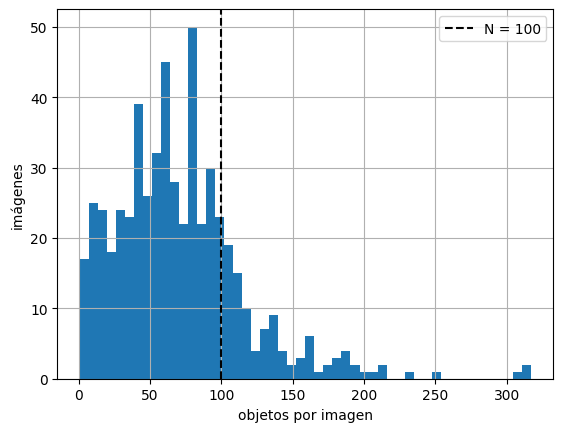

In [7]:
# Densidad: objetos por imagen y techo de recall (sin modelo) para N = 100, 300, 500
cnt = objects_per_image('../data/val_sub.json'); n = pd.Series(cnt)
print(n.describe())
rows = []
for N in (100, 300, 500):
    rows.append({'N': N, '% imágenes con n > N': round(100 * (n > N).mean(), 1),
                 'techo de recall (dataset)': round(100 * oracle_recall(cnt, N), 1)})
    print(f'N={N}: imágenes con más de N objetos = {(n > N).mean():.1%} | techo de recall = {oracle_recall(cnt, N):.1%}')
pd.DataFrame(rows).to_csv('../results/techo_recall.csv', index=False)
groups, (q1, q2) = density_groups('../data/val_sub.json')
print({k: len(v) for k, v in groups.items()}, 'cortes de terciles:', q1, q2)
n.hist(bins=50); plt.axvline(100, color='k', ls='--', label='N = 100'); plt.legend()
plt.xlabel('objetos por imagen'); plt.ylabel('imágenes'); plt.savefig('../results/hist_objetos.png', dpi=150, bbox_inches='tight')

**Lectura.** 106 de las 548 imágenes de validación (19,3 %) contienen más de 100 objetos; con N = 100, el techo de recall del conjunto es 89,0 %, es decir, el 11 % de los objetos no es alcanzable ni siquiera con un detector perfecto. Con N = 300 el techo asciende a 99,9 % (3 imágenes superan 300 objetos; máximo: 317) y con N = 500 a 100 %, por lo que N = 500 no modifica la cota respecto de N = 300 (D17).

El techo es una cota analítica, no una medición: H1 solo puede confirmarse si el recall medido de N = 100 en el grupo `gt100` se aproxima a min(1, 100/n). Un recall muy inferior indicaría que la restricción activa es la detección de objetos pequeños y no el número de queries.